# SentinelX AI — Baseline de prédiction du RUL

**Dataset NASA C-MAPSS FD001 · Étape S3 du projet**

### Qu'est-ce qu'une baseline ?

Une **baseline** (modèle de référence) est un premier modèle simple, construit et évalué proprement **avant** les modèles plus complexes. Elle sert d'étalon : le réseau LSTM/GRU de l'étape S4 (des réseaux de neurones qui lisent une séquence de cycles) n'aura d'intérêt que s'il fait **mieux** que cette baseline, mesuré de la même façon.

### Ce que nous allons faire

1. Charger les données et reprendre les décisions de l'EDA.
2. Construire des **features** (variables d'entrée du modèle) décrivant l'historique récent de chaque moteur.
3. Comparer deux modèles : une **régression linéaire** et une **forêt aléatoire** (*Random Forest*).
4. Faire tous nos choix par **validation croisée** sur les 80 moteurs d'entraînement.
5. Vérifier **une fois** le modèle choisi sur les **20 moteurs de validation**.
6. Évaluer le modèle final sur le **jeu de test** officiel de la NASA.

### Trois groupes de moteurs, trois rôles

| Groupe | Moteurs | Rôle |
|---|---|---|
| Entraînement | 80 moteurs du train | le modèle apprend ; nous comparons les options par **validation croisée** (5 tours) |
| Validation | 20 moteurs du train | jamais utilisés pour choisir : ils vérifient **une fois** le modèle choisi |
| Test | 100 moteurs de `test_FD001.txt` | examen final officiel, à la fin |

C'est le même principe que pour un examen : on s'entraîne sur des exercices (entraînement), on vérifie son niveau sur des exercices corrigés qu'on n'a pas utilisés pour réviser (validation), puis on passe l'examen final (test).

### Comment lire ce notebook

Chaque étape suit le même plan : **Ce que nous faisons** (l'objectif), **Pourquoi** (l'utilité pour SentinelX AI), **Comment** (le fonctionnement du code), **Résultats** (ce que montrent les sorties) et **Interprétation** (ce que nous pouvons en conclure).

## 1. Préparation du notebook

**Ce que nous faisons.** Nous importons les bibliothèques et nous fixons les paramètres utilisés dans tout le notebook.

**Comment.** `pandas` manipule les tableaux de données, `numpy` fait les calculs, `matplotlib` et `seaborn` tracent les graphiques, `scikit-learn` fournit les modèles, les métriques et `GroupKFold`, et `joblib` enregistre le modèle entraîné dans un fichier. La **graine** (`RANDOM_STATE`) fixe le hasard de la forêt aléatoire : chaque exécution donne exactement les mêmes résultats.

In [1]:
from pathlib import Path
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)

RANDOM_STATE = 42   # graine : mêmes résultats à chaque exécution
N_START = 20        # « début de vie » d'un moteur : ses 20 premiers cycles
                    # (assez pour une moyenne stable, et chaque moteur de test en a au moins 31)

In [2]:
# Le notebook peut être lancé depuis la racine du projet ou depuis le dossier notebooks/.
if Path("data/raw").exists():
    PROJECT_ROOT = Path(".")
else:
    PROJECT_ROOT = Path("..")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
EDA_DIR = PROJECT_ROOT / "artifacts" / "eda_fd001"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "baseline_fd001"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "baseline_fd001"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Données et décisions de l'EDA

**Ce que nous faisons.** Nous chargeons le train et nous relisons les décisions de l'EDA : quels moteurs sont en validation, quels capteurs utiliser, la taille de l'historique et la zone d'évaluation.

**Pourquoi relire au lieu de refaire ?** Pour être certains d'utiliser **exactement** les mêmes moteurs de validation et les mêmes capteurs que l'EDA. Une décision n'est prise qu'à un seul endroit.

**Comment.**

- `json.loads` lit les trois fichiers JSON écrits par l'EDA.
- `pd.read_csv` lit le fichier texte de la NASA ; nous donnons nous-mêmes le nom des 26 colonnes.
- Nous vérifions que le fichier a bien 20 631 lignes, comme dans l'EDA. Si le fichier avait changé, le notebook s'arrêterait ici. (L'EDA vérifie en plus l'empreinte SHA-256 complète des fichiers.)
- **Le RUL** se calcule moteur par moteur : RUL = dernier cycle du moteur − cycle courant. `groupby("unit_id")["cycle"].transform("max")` donne, sur chaque ligne, le dernier cycle de son moteur.

> **Exemple.** Un moteur tombe en panne au cycle 5. Aux cycles 1, 2, 3, 4, 5, son RUL vaut 4, 3, 2, 1, 0.

In [3]:
split = json.loads((EDA_DIR / "fd001_engine_split.json").read_text(encoding="utf-8"))
groups = json.loads((EDA_DIR / "fd001_feature_groups.json").read_text(encoding="utf-8"))
eda_summary = json.loads((EDA_DIR / "eda_fd001_summary.json").read_text(encoding="utf-8"))

SENSORS = groups["selected_sensors"]
TRAIN_ENGINES = split["analysis_engines"]          # 80 moteurs d'entraînement
VALIDATION_ENGINES = split["validation_engines"]   # 20 moteurs de validation
WINDOW = eda_summary["history_window"]             # historique : les 30 derniers cycles
EVAL_HORIZON = eda_summary["evaluation_horizon"]   # zone d'évaluation : RUL réel <= 127

print(len(SENSORS), "capteurs :", SENSORS)
print("Moteurs de validation :", VALIDATION_ENGINES)
print("Historique :", WINDOW, "cycles · zone d'évaluation : RUL <=", EVAL_HORIZON)

14 capteurs : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Moteurs de validation : [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]
Historique : 30 cycles · zone d'évaluation : RUL <= 127


In [4]:
COLUMN_NAMES = (["unit_id", "cycle", "setting_1", "setting_2", "setting_3"]
                + [f"sensor_{i}" for i in range(1, 22)])

train_path = RAW_DIR / "train_FD001.txt"
train_df = pd.read_csv(train_path, sep=r"\s+", header=None, names=COLUMN_NAMES)
assert len(train_df) == eda_summary["train_rows"]      # même fichier que dans l'EDA

# Cible : RUL = dernier cycle du moteur - cycle courant (même calcul que dans l'EDA).
last_cycle = train_df.groupby("unit_id")["cycle"].transform("max")
train_df["RUL"] = last_cycle - train_df["cycle"]
train_df[["unit_id", "cycle"] + SENSORS[:3] + ["RUL"]].head()

,unit_id,cycle,sensor_2,sensor_3,sensor_4,RUL
0,1,1,641.82,1589.70,1400.60,191
1,1,2,642.15,1591.82,1403.14,190
2,1,3,642.35,1587.99,1404.20,189
3,1,4,642.35,1582.79,1401.87,188
4,1,5,642.37,1582.85,1406.22,187


## 3. Features : donner au modèle l'historique récent

**Ce que nous faisons.** Pour chaque capteur, nous calculons trois nouvelles colonnes (des **features**, c'est-à-dire des entrées du modèle) :

| Feature | Calcul au cycle *t* | Pourquoi (constat de l'EDA) |
|---|---|---|
| `_mean` | moyenne des 30 derniers cycles | les mesures sont bruitées : la moyenne est plus fiable qu'une seule valeur |
| `_slope` | pente de la droite qui passe au mieux par les 30 derniers points | la dégradation **s'accélère** : la pente mesure la vitesse d'évolution du capteur |
| `_delta` | mesure actuelle − niveau de départ du moteur | chaque moteur part d'un **niveau différent** : on mesure le changement depuis son propre départ |

**Règle importante : utiliser seulement le passé.** Au cycle *t*, chaque feature n'utilise que les cycles déjà observés **du même moteur**. En situation réelle, le futur n'existe pas encore.

**Comment : trois petites fonctions, une par feature.**

1. **`rolling_mean` — la moyenne glissante.** `rolling(30)` crée une « fenêtre glissante » : à chaque ligne, elle regarde cette ligne et les 29 précédentes, puis `.mean()` en fait la moyenne. Au début de vie, il y a moins de 30 cycles : `min_periods=1` autorise alors la moyenne des cycles disponibles.
2. **`rolling_slope` — la pente.** Une boucle `for` parcourt les cycles. À chaque cycle, elle prend les 30 dernières valeurs (moins au début de vie) et calcule leur pente avec `compute_slope`. Au premier cycle, il n'y a qu'une valeur : pas de pente, on met 0.
   - `np.polyfit(x, y, 1)` cherche la droite *y = a·x + b* la plus proche des points (méthode des moindres carrés). Il renvoie `[a, b]` : le premier élément `a` est la **pente**, en unités de capteur par cycle.
   - Une pente positive veut dire que le capteur augmente ; une pente proche de 0, qu'il est stable.
3. **`delta_from_start` — l'écart au début de vie.**
   - La **référence** est le niveau de départ du moteur : la moyenne de ses 20 premiers cycles.
   - Avant le cycle 20, ces 20 cycles ne sont pas encore tous connus. La référence est alors la moyenne des cycles **déjà vus** : c'est ce que calcule `expanding().mean()` (une fenêtre qui commence au premier cycle et s'agrandit à chaque ligne).
   - À partir du cycle 21, la référence est **figée** à la moyenne des 20 premiers cycles.
   - `delta` = mesure actuelle − référence.
4. **`add_history_features`** traite les moteurs **un par un** (boucle `for` sur `groupby("unit_id")`) et appelle les trois fonctions pour chaque capteur : les calculs ne mélangent jamais deux moteurs.

> **Exemple de pente.** Si un capteur vaut 10, 12, 14, 16 sur quatre cycles, il augmente de 2 unités par cycle : sa pente vaut 2. S'il reste stable, sa pente vaut 0.

In [5]:
def compute_slope(values):
    # Pente de la droite qui passe au mieux par ces valeurs (en unités par cycle).
    cycles = np.arange(len(values))                  # 0, 1, 2, ... : la position de chaque cycle
    slope, intercept = np.polyfit(cycles, values, 1)  # droite y = slope * x + intercept
    return slope


print("Pente de [10, 12, 14, 16] :", round(float(compute_slope(np.array([10, 12, 14, 16]))), 2))
print("Pente de [5, 5, 5, 5] proche de 0 :", np.isclose(compute_slope(np.array([5, 5, 5, 5])), 0))

Pente de [10, 12, 14, 16] : 2.0
Pente de [5, 5, 5, 5] proche de 0 : True


In [6]:
def rolling_mean(values, window):
    # Moyenne des `window` dernières valeurs (ou des valeurs disponibles en début de vie).
    return values.rolling(window, min_periods=1).mean()


def rolling_slope(values, window):
    # Pour chaque cycle : pente des `window` dernières valeurs (0 au premier cycle).
    slopes = []
    for position in range(len(values)):
        first = max(0, position - window + 1)        # début de la fenêtre (jamais avant le 1er cycle)
        recent_values = values[first:position + 1]   # valeurs déjà observées, au plus `window`
        if len(recent_values) < 2:
            slopes.append(0.0)                       # une seule valeur : pas de pente
        else:
            slopes.append(compute_slope(recent_values))
    return slopes


def delta_from_start(values, cycles, n_start):
    # Écart entre la mesure actuelle et le niveau de départ du moteur.
    reference = values.expanding().mean()                # avant le cycle n_start : moyenne des cycles déjà vus
    start_level = values[cycles <= n_start].mean()       # moyenne des n_start premiers cycles
    reference[cycles > n_start] = start_level            # ensuite : référence figée
    return values - reference

In [7]:
def add_history_features(df, sensors, window, n_start):
    # Ajoute les colonnes _mean, _slope et _delta de chaque capteur, en traitant les moteurs un par un.
    df = df.sort_values(["unit_id", "cycle"])
    engine_tables = []
    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.copy()
        for sensor in sensors:
            values = engine[sensor]
            engine[sensor + "_mean"] = rolling_mean(values, window)
            engine[sensor + "_slope"] = rolling_slope(values.to_numpy(dtype=float), window)
            engine[sensor + "_delta"] = delta_from_start(values, engine["cycle"], n_start)
        engine_tables.append(engine)
    return pd.concat(engine_tables)


train_feat = add_history_features(train_df, SENSORS, WINDOW, N_START)

INSTANT_FEATURES = SENSORS                          # 14 mesures du cycle courant
HISTORY_FEATURES = []                               # 42 features d'historique, toujours dans cet ordre
for suffix in ["_mean", "_slope", "_delta"]:
    for sensor in SENSORS:
        HISTORY_FEATURES.append(sensor + suffix)
print("Features instantanées :", len(INSTANT_FEATURES), "· features d'historique :", len(HISTORY_FEATURES))

Features instantanées : 14 · features d'historique : 42


### Exemple : un moteur fictif de 5 cycles

Pour bien voir les calculs, prenons un moteur imaginaire avec un seul capteur, une fenêtre de **3** cycles (au lieu de 30) et un début de vie de **2** cycles (au lieu de 20). Calculons d'abord à la main :

| Cycle | Mesure | `_mean` (3 derniers cycles) | `_slope` (3 derniers cycles) | Référence | `_delta` |
|---|---|---|---|---|---|
| 1 | 100 | 100 (un seul cycle) | 0 (une seule valeur) | 100 (cycles vus : 1) | 0 |
| 2 | 102 | (100 + 102) / 2 = 101 | 2 (de 100 à 102) | 101 (cycles vus : 1-2) | 1 |
| 3 | 101 | (100 + 102 + 101) / 3 = 101 | 0,5 | 101 (figée) | 0 |
| 4 | 105 | (102 + 101 + 105) / 3 ≈ 102,67 | 1,5 | 101 | 4 |
| 5 | 108 | (101 + 105 + 108) / 3 ≈ 104,67 | 3,5 | 101 | 7 |

À partir du cycle 3, la référence est figée à la moyenne des 2 premiers cycles : (100 + 102) / 2 = 101. La cellule suivante vérifie que le code retrouve exactement ces valeurs.

In [8]:
toy_engine = pd.DataFrame({"unit_id": 1, "cycle": [1, 2, 3, 4, 5], "sensor_x": [100, 102, 101, 105, 108]})
toy_features = add_history_features(toy_engine, ["sensor_x"], window=3, n_start=2)

assert np.allclose(toy_features["sensor_x_mean"], [100, 101, 101, 308 / 3, 314 / 3])
assert np.allclose(toy_features["sensor_x_slope"], [0, 2, 0.5, 1.5, 3.5])
assert np.allclose(toy_features["sensor_x_delta"], [0, 1, 0, 4, 7])
toy_features.round(2)

,unit_id,cycle,sensor_x,sensor_x_mean,sensor_x_slope,sensor_x_delta
0,1,1,100,100.00,0.0,0.0
1,1,2,102,101.00,2.0,1.0
2,1,3,101,101.00,0.5,0.0
3,1,4,105,102.67,1.5,4.0
4,1,5,108,104.67,3.5,7.0


**Vérification : le futur ne doit pas influencer le passé.** Nous modifions les mesures d'un vrai moteur **après** le cycle 60, puis nous recalculons ses features. Les features des cycles 1 à 60 ne doivent pas changer.

`.loc[condition, colonnes]` sélectionne les lignes qui vérifient la condition (ici : cycle > 60) et les colonnes indiquées, pour les modifier.

In [9]:
engine_2 = train_df[train_df["unit_id"] == 2]
modified = engine_2.copy()
modified.loc[modified["cycle"] > 60, SENSORS] += 1000          # on « falsifie » le futur

features_before = add_history_features(engine_2, SENSORS, WINDOW, N_START)
features_after = add_history_features(modified, SENSORS, WINDOW, N_START)
past = features_before["cycle"] <= 60
assert np.allclose(features_before.loc[past, HISTORY_FEATURES], features_after.loc[past, HISTORY_FEATURES])
print("Vérifié : modifier le futur ne change pas les features du passé.")

Vérifié : modifier le futur ne change pas les features du passé.


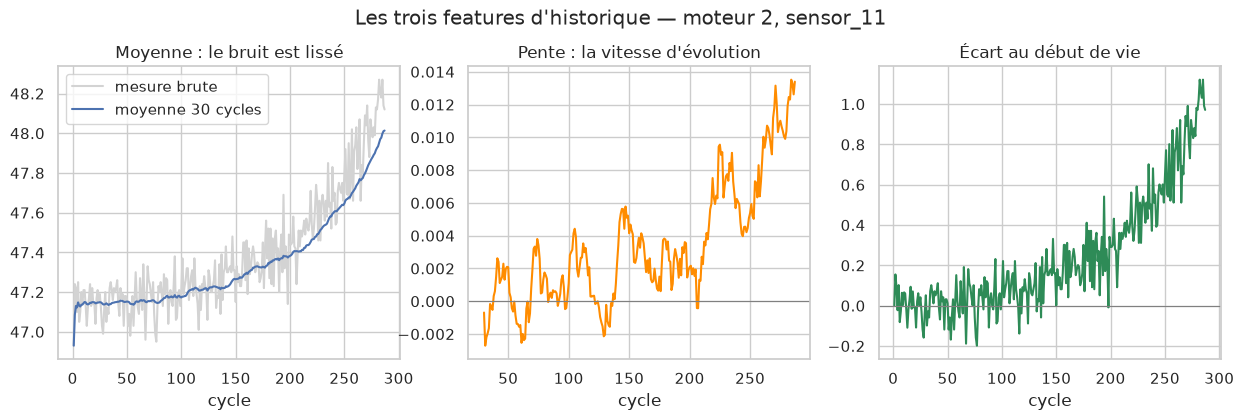

In [10]:
# Illustration sur le moteur 2, capteur sensor_11.
engine = train_feat[train_feat["unit_id"] == 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(engine["cycle"], engine["sensor_11"], color="lightgray", label="mesure brute")
axes[0].plot(engine["cycle"], engine["sensor_11_mean"], label="moyenne 30 cycles")
axes[0].set_title("Moyenne : le bruit est lissé")
full_window = engine[engine["cycle"] >= WINDOW]          # à partir du cycle 30 : la fenêtre est complète
axes[1].plot(full_window["cycle"], full_window["sensor_11_slope"], color="darkorange")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("Pente : la vitesse d'évolution")
axes[2].plot(engine["cycle"], engine["sensor_11_delta"], color="seagreen")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_title("Écart au début de vie")
axes[0].legend()
for ax in axes:
    ax.set_xlabel("cycle")
fig.suptitle("Les trois features d'historique — moteur 2, sensor_11", y=1.03)
fig.savefig(FIGURE_DIR / "01_features_historique.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats.** Les vérifications montrent que la pente est bien calculée (2 pour la suite 10, 12, 14, 16), que le code retrouve exactement les valeurs calculées à la main sur le moteur fictif, et que le futur n'influence pas le passé. Sur le graphique :

- la **moyenne** suit la tendance du capteur sans le bruit ;
- la **pente** reste proche de 0 pendant la phase saine, puis augmente à l'approche de la panne (graphique tracé à partir du cycle 30, quand la fenêtre est complète) ;
- l'**écart au début de vie** part de 0 et grandit avec la dégradation, quel que soit le niveau de départ du moteur.

**Interprétation.** Ces 42 features donnent au modèle une information qu'une seule mesure ne contient pas : un niveau lissé, une vitesse d'évolution et un changement par rapport au départ. L'expérience 1 va vérifier si cela améliore vraiment la prédiction.

## 4. Les modèles et la façon de les évaluer

### Les deux modèles

**Régression linéaire.** Le modèle calcule une somme pondérée des features : RUL ≈ a + b₁ × feature₁ + b₂ × feature₂ + … C'est simple, rapide et facile à expliquer, mais le modèle ne peut représenter que des relations **en ligne droite**.

- *Comment elle s'entraîne :* `model.fit(X, y)` choisit les poids a, b₁, b₂… qui rendent la somme des erreurs au carré la plus petite possible sur les lignes d'entraînement (méthode des moindres carrés). Il n'y a aucun réglage à choisir.

**Forêt aléatoire (*Random Forest*).** Un **arbre de décision** pose une suite de questions, par exemple : « la pente de `sensor_11` dépasse-t-elle 0,01 ? », puis « la moyenne de `sensor_4` dépasse-t-elle 1 410 ? ». Il prédit ensuite le RUL moyen des lignes d'entraînement qui ont donné les mêmes réponses. Une forêt fait la **moyenne de 100 arbres** légèrement différents, ce qui rend la prédiction plus stable. Elle peut représenter des relations qui ne sont pas des lignes droites, comme la dégradation « lente puis accélérée » vue dans l'EDA.

- *Comment elle s'entraîne :* `model.fit(X, y)` construit les 100 arbres. Chaque arbre apprend sur un tirage au hasard des lignes d'entraînement. À chaque question, il essaie une partie des features (réglage `max_features`) et garde la question qui réduit le plus l'erreur. `model.predict(X)` fait ensuite la moyenne des réponses des 100 arbres.

Réglages de la forêt (des **hyperparamètres**, c'est-à-dire des réglages choisis par nous et non appris) :

| Réglage | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 100 | nombre d'arbres |
| `min_samples_leaf` | 5 | chaque réponse finale repose sur au moins 5 lignes, pour éviter d'apprendre le bruit par cœur |
| `max_features` | 0,33 | à chaque question, l'arbre ne regarde qu'un tiers des features, tiré au hasard. Les arbres deviennent plus différents les uns des autres, et leur moyenne est plus fiable. Règle habituelle pour la régression, **vérifiée par validation croisée à l'expérience 3** |

> Ces deux modèles n'ont pas besoin de **normalisation** (mettre toutes les features à la même échelle). La régression linéaire donne les mêmes prédictions avec ou sans, et un arbre compare une feature à un seuil, donc l'échelle ne change rien. La normalisation sera nécessaire pour le LSTM/GRU, et devra alors être calculée sur les moteurs d'entraînement uniquement.

In [11]:
def create_model(model_name, max_features=0.33):
    # Crée un modèle neuf, pas encore entraîné (max_features ne concerne que la forêt).
    if model_name == "Régression linéaire":
        return LinearRegression()
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=max_features,
                                 random_state=RANDOM_STATE, n_jobs=-1)


MODEL_NAMES = ["Régression linéaire", "Forêt aléatoire"]

### Les métriques

Pour chaque ligne, l'**erreur** est : RUL prédit − RUL réel.

| Métrique | Calcul | Lecture |
|---|---|---|
| **MAE** | moyenne des erreurs en valeur absolue | « en moyenne, le modèle se trompe de … cycles » |
| **RMSE** | racine de la moyenne des erreurs au carré | en cycles aussi, mais les grosses erreurs comptent davantage. C'est la métrique principale du projet. |
| **R²** | 1 − (erreurs du modèle) / (erreurs si l'on prédisait toujours la moyenne) | 1 = parfait, 0 = pas mieux que la moyenne |

**Petit exemple.** Trois moteurs ont un RUL réel de 10, 50 et 100 cycles, et le modèle prédit 12, 40 et 110. Les erreurs valent 2, −10 et 10.

In [12]:
def compute_metrics(y_true, y_pred):
    # MAE, RMSE et R2 (les deux premiers en cycles).
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


example = compute_metrics([10, 50, 100], [12, 40, 110])
print("MAE  =", round(example["MAE"], 2), "  -> (2 + 10 + 10) / 3")
print("RMSE =", round(example["RMSE"], 2), "  -> racine de (4 + 100 + 100) / 3 : plus grand que la MAE")
print("R²   =", round(example["R2"], 3))

MAE  = 7.33   -> (2 + 10 + 10) / 3
RMSE = 8.25   -> racine de (4 + 100 + 100) / 3 : plus grand que la MAE
R²   = 0.95


### Comment nous comparons les options : la validation croisée par moteur

**1. Pourquoi séparer par moteur ?** Les cycles successifs d'un même moteur se ressemblent beaucoup. Si un moteur avait des lignes à la fois en apprentissage et en contrôle, le modèle le « reconnaîtrait » et paraîtrait meilleur qu'il ne l'est. Nous plaçons donc toujours **toutes les lignes d'un moteur du même côté**.

**2. Comment les 5 groupes sont construits.** `GroupKFold(n_splits=5)` reçoit la colonne `unit_id` comme « groupes » et répartit les 80 moteurs d'entraînement en **5 groupes de 16 moteurs**. La répartition ne dépend pas du hasard : ce sont les mêmes groupes à chaque exécution.

**3. Qu'est-ce qu'un *fold* ?** Un *fold* est un **tour** de la validation croisée :

| Tour | Le modèle apprend sur | Le modèle est contrôlé sur |
|---|---|---|
| 1 | groupes 2, 3, 4, 5 (64 moteurs) | groupe 1 (16 moteurs) |
| 2 | groupes 1, 3, 4, 5 | groupe 2 |
| … | … | … |
| 5 | groupes 1, 2, 3, 4 | groupe 5 |

Chaque moteur est donc contrôlé **une fois**, par un modèle qui ne l'a **jamais vu**.

**4. L'entraînement dans chaque tour** (fonction `train_and_predict`) : un modèle neuf apprend sur les 64 moteurs. Si un **plafond** est choisi, il apprend `min(RUL, plafond)` au lieu du RUL brut (voir EDA, section 7). Il prédit ensuite le RUL de toutes les lignes des 16 moteurs de contrôle. Les prédictions négatives sont ramenées à 0, car un RUL ne peut pas être négatif.

**5. Les métriques de chaque tour** (fonction `evaluate_on_zone`) : nous gardons seulement la **zone utile**, les lignes dont le RUL réel est ≤ 127, et nous comparons toujours au **vrai** RUL (jamais plafonné). C'est là que la maintenance doit agir, et cela permet de comparer des plafonds différents.

**6. La moyenne** (fonction `cross_validate`) : les 5 tours donnent 5 RMSE. Le score d'une option est leur **moyenne** ; leur **écart-type** indique si le résultat est stable d'un groupe de moteurs à l'autre.

**7. Le choix.** Pour chaque question (features, plafond, `max_features`), nous gardons l'option qui a le **plus petit RMSE moyen**. Cette règle est fixée à l'avance et n'utilise jamais le test.

**Un détail de code : des numéros de lignes aux numéros de moteurs.** `GroupKFold` renvoie, pour chaque tour, deux listes de **positions de lignes** : `fit_index` (les lignes pour apprendre) et `check_index` (les lignes pour contrôler). `.iloc` sélectionne des lignes par leur position (0, 1, 2…). Nous transformons tout de suite ces positions en **listes de numéros de moteurs** ; ensuite, nous choisissons les lignes avec `isin` (« le moteur fait-il partie de cette liste ? »). Le code ne dépend donc pas de l'index du tableau (pas besoin de `reset_index`), et les listes de moteurs sont faciles à afficher et à réutiliser en S4.

**Et les 20 moteurs de validation ?** Ils ne servent à **aucun** choix. Nous les gardons pour vérifier **une seule fois** le modèle choisi (section 7). C'est une deuxième estimation honnête, avant le test.

In [13]:
train_part = train_feat[train_feat["unit_id"].isin(TRAIN_ENGINES)]                # 80 moteurs
validation_feat = train_feat[train_feat["unit_id"].isin(VALIDATION_ENGINES)]      # 20 moteurs

# GroupKFold : 5 groupes de moteurs ; toutes les lignes d'un moteur restent dans le même groupe.
group_kfold = GroupKFold(n_splits=5)
folds = []      # pour chaque tour : (moteurs pour apprendre, moteurs pour contrôler)
for fit_index, check_index in group_kfold.split(train_part, groups=train_part["unit_id"]):
    fit_engines = sorted(train_part["unit_id"].iloc[fit_index].unique().tolist())
    check_engines = sorted(train_part["unit_id"].iloc[check_index].unique().tolist())
    folds.append((fit_engines, check_engines))

fold_number = 1
for fit_engines, check_engines in folds:
    assert set(fit_engines).isdisjoint(check_engines)      # aucun moteur des deux côtés
    print(f"Tour {fold_number} : apprentissage sur {len(fit_engines)} moteurs, contrôle sur les moteurs {check_engines}")
    fold_number += 1

Tour 1 : apprentissage sur 64 moteurs, contrôle sur les moteurs [10, 17, 29, 30, 47, 51, 57, 59, 63, 66, 68, 69, 80, 90, 99, 100]
Tour 2 : apprentissage sur 64 moteurs, contrôle sur les moteurs [8, 12, 14, 21, 22, 39, 44, 53, 60, 76, 86, 88, 89, 92, 94, 97]
Tour 3 : apprentissage sur 64 moteurs, contrôle sur les moteurs [15, 20, 26, 28, 33, 37, 41, 48, 52, 55, 61, 64, 65, 70, 85, 96]
Tour 4 : apprentissage sur 64 moteurs, contrôle sur les moteurs [6, 7, 16, 24, 25, 35, 36, 38, 50, 67, 73, 79, 82, 87, 93, 95]
Tour 5 : apprentissage sur 64 moteurs, contrôle sur les moteurs [2, 3, 4, 9, 18, 27, 42, 43, 49, 56, 58, 62, 72, 75, 83, 98]


In [14]:
def train_and_predict(model_name, train_data, predict_data, feature_columns, cap, max_features=0.33):
    # Entraîne un modèle neuf sur train_data, puis prédit le RUL des lignes de predict_data.
    target = train_data["RUL"]
    if cap is not None:
        target = target.clip(upper=cap)                 # RUL plafonné : min(RUL, cap)
    model = create_model(model_name, max_features)
    model.fit(train_data[feature_columns], target)
    predictions = model.predict(predict_data[feature_columns])
    predictions = np.clip(predictions, 0, None)        # pas de RUL négatif
    return model, predictions


def evaluate_on_zone(true_rul, predictions):
    # Métriques sur la zone utile (RUL réel <= 127), en comparant au vrai RUL.
    true_rul = np.asarray(true_rul)
    predictions = np.asarray(predictions)
    in_zone = true_rul <= EVAL_HORIZON                  # True pour les lignes de la zone utile
    return compute_metrics(true_rul[in_zone], predictions[in_zone])


def cross_validate(model_name, feature_columns, cap, max_features=0.33):
    # Validation croisée : un modèle par tour, puis moyenne des 5 tours (et écart-type du RMSE).
    fold_metrics = []
    for fit_engines, check_engines in folds:
        fit_data = train_part[train_part["unit_id"].isin(fit_engines)]          # 64 moteurs pour apprendre
        check_data = train_part[train_part["unit_id"].isin(check_engines)]      # 16 moteurs pour contrôler
        _, predictions = train_and_predict(model_name, fit_data, check_data, feature_columns, cap, max_features)
        fold_metrics.append(evaluate_on_zone(check_data["RUL"], predictions))
    fold_table = pd.DataFrame(fold_metrics)             # 5 lignes (une par tour), colonnes MAE, RMSE, R2
    return {"RMSE": fold_table["RMSE"].mean(), "RMSE écart-type": fold_table["RMSE"].std(),
            "MAE": fold_table["MAE"].mean(), "R2": fold_table["R2"].mean()}

## 5. Expérience 1 — L'historique améliore-t-il la prédiction ?

**Ce que nous faisons.** Nous comparons, pour les deux modèles :

- les **14 mesures du cycle courant** (features instantanées) ;
- les **42 features d'historique** (moyenne, pente, écart au début de vie).

**Pourquoi.** Construire des features n'a d'intérêt que si elles améliorent vraiment la prédiction.

**Comment.** Chaque option passe par `cross_validate` (5 tours). Le résultat de chaque option devient une ligne d'un tableau. Pour cette première expérience, le RUL est plafonné à 125, la valeur illustrative de l'EDA ; le plafond sera choisi à l'expérience 2. Cette cellule prend environ une minute.

In [15]:
experiment_1 = []
for model_name in MODEL_NAMES:
    for set_name, features in [("instantanées (14)", INSTANT_FEATURES), ("historique (42)", HISTORY_FEATURES)]:
        metrics = cross_validate(model_name, features, cap=125)
        experiment_1.append({"modèle": model_name, "features": set_name,
                             "RMSE": metrics["RMSE"], "RMSE écart-type": metrics["RMSE écart-type"],
                             "MAE": metrics["MAE"], "R2": metrics["R2"]})

experiment_1 = pd.DataFrame(experiment_1)
experiment_1

,modèle,features,RMSE,RMSE écart-type,MAE,R2
0,Régression linéaire,instantanées (14),21.60,2.63,17.65,0.65
1,Régression linéaire,historique (42),18.16,0.77,14.88,0.76
2,Forêt aléatoire,instantanées (14),20.68,3.08,15.25,0.68
3,Forêt aléatoire,historique (42),13.78,0.76,10.04,0.86


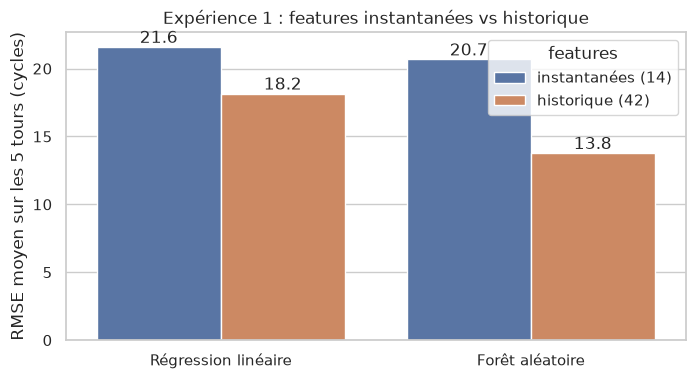

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=experiment_1, x="modèle", y="RMSE", hue="features", ax=ax)
ax.set(ylabel="RMSE moyen sur les 5 tours (cycles)", xlabel="", title="Expérience 1 : features instantanées vs historique")
# ax.containers contient les groupes de barres du graphique : bar_label écrit la valeur au-dessus de chaque barre.
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.1f")
fig.savefig(FIGURE_DIR / "02_choix_features.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats** (RMSE moyen sur les 5 tours de validation croisée, en cycles) :

| | instantanées (14) | historique (42) |
|---|---|---|
| Régression linéaire | 21,6 | 18,2 |
| Forêt aléatoire | 20,7 | **13,8** |

**Interprétation.**

- L'historique **améliore les deux modèles**. La forêt aléatoire en profite le plus : son erreur passe de 20,7 à 13,8 cycles.
- L'historique rend aussi les résultats plus **stables** d'un tour à l'autre : l'écart-type entre les tours passe de 2,6 à 3,1 cycles à moins de 0,8 cycle.
- Avec les seules mesures du cycle courant, les deux modèles sont proches : sans historique, aucun ne voit la vitesse de dégradation.
- La forêt profite davantage de l'historique. Une explication probable : elle peut représenter une relation qui n'est pas une ligne droite, comme la dégradation « lente puis accélérée » vue dans l'EDA.

**Nous gardons les 42 features d'historique.**

## 6. Expérience 2 — Quel plafond de RUL ?

**Ce que nous faisons.** Avec les features d'historique, nous comparons le RUL **brut** (sans plafond) et quatre plafonds : 100, 110, 125 et 140 cycles.

**Pourquoi.** En début de vie, les capteurs ne bougent presque pas : il est impossible de distinguer un moteur à 250 cycles de la panne d'un moteur à 300. Le **plafond** dit au modèle : « au-delà de cette valeur, réponds simplement *moteur en bonne santé* ». Un plafond trop bas empêche de prédire les RUL moyens ; un plafond trop haut oblige le modèle à apprendre des valeurs que les capteurs ne permettent pas de distinguer. Le cahier des charges demande de choisir cette valeur par validation.

**Comment.** Le plafond ne change que la **cible d'apprentissage** (`min(RUL, plafond)` dans `train_and_predict`). L'évaluation compare toujours au vrai RUL, ce qui rend les plafonds comparables entre eux. Ensuite, pour chaque modèle, nous retenons le plafond au plus petit RMSE moyen, puis le modèle au plus petit RMSE moyen.

In [17]:
experiment_2 = []
for model_name in MODEL_NAMES:
    for cap in [None, 100, 110, 125, 140]:
        metrics = cross_validate(model_name, HISTORY_FEATURES, cap=cap)
        if cap is None:
            cap_label = "sans"
        else:
            cap_label = cap
        experiment_2.append({"modèle": model_name, "plafond": cap_label,
                             "RMSE": metrics["RMSE"], "RMSE écart-type": metrics["RMSE écart-type"],
                             "MAE": metrics["MAE"], "R2": metrics["R2"]})

experiment_2 = pd.DataFrame(experiment_2)
experiment_2.pivot(index="plafond", columns="modèle", values="RMSE").round(2)

modèle,Forêt aléatoire,Régression linéaire
plafond,,
100,13.54,17.12
110,12.85,16.76
125,13.78,18.16
140,15.71,20.69
sans,23.71,32.45


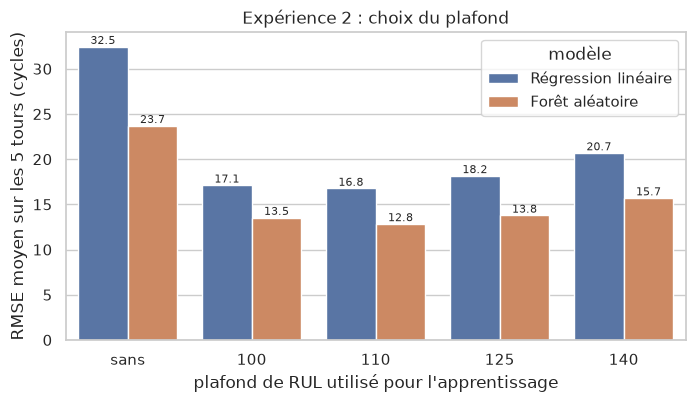

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=experiment_2, x="plafond", y="RMSE", hue="modèle", ax=ax)
ax.set(xlabel="plafond de RUL utilisé pour l'apprentissage", ylabel="RMSE moyen sur les 5 tours (cycles)",
       title="Expérience 2 : choix du plafond")
for bar_group in ax.containers:                   # valeur écrite au-dessus de chaque barre
    ax.bar_label(bar_group, fmt="%.1f", fontsize=8)
fig.savefig(FIGURE_DIR / "03_choix_plafond.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Pour chaque modèle, nous retenons le plafond qui donne le plus petit RMSE moyen en validation croisée.
best_cap = {}
best_rmse = {}
for model_name in MODEL_NAMES:
    rows = experiment_2[(experiment_2["modèle"] == model_name) & (experiment_2["plafond"] != "sans")]
    best_row = rows.sort_values("RMSE").iloc[0]          # .iloc[0] : la première ligne, donc le plus petit RMSE
    best_cap[model_name] = int(best_row["plafond"])
    best_rmse[model_name] = best_row["RMSE"]

# Le modèle retenu est celui qui obtient le plus petit RMSE moyen en validation croisée.
if best_rmse["Forêt aléatoire"] < best_rmse["Régression linéaire"]:
    SELECTED_MODEL = "Forêt aléatoire"
else:
    SELECTED_MODEL = "Régression linéaire"

print("Plafond retenu :", best_cap)
print("RMSE moyen en validation croisée :", {m: round(float(v), 2) for m, v in best_rmse.items()})
print("Modèle retenu :", SELECTED_MODEL)

Plafond retenu : {'Régression linéaire': 110, 'Forêt aléatoire': 110}
RMSE moyen en validation croisée : {'Régression linéaire': 16.76, 'Forêt aléatoire': 12.85}
Modèle retenu : Forêt aléatoire


**Résultats** (RMSE moyen sur les 5 tours, en cycles) :

| Plafond | sans | 100 | 110 | 125 | 140 |
|---|---|---|---|---|---|
| Régression linéaire | 32,5 | 17,1 | **16,8** | 18,2 | 20,7 |
| Forêt aléatoire | 23,7 | 13,5 | **12,8** | 13,8 | 15,7 |

**Interprétation.**

- **Plafonner le RUL est indispensable.** Sans plafond, l'erreur est beaucoup plus grande : le modèle essaie d'apprendre les grands RUL du début de vie, au lieu de bien prédire près de la panne.
- Le meilleur plafond est **110 cycles pour les deux modèles**. En dessous, le modèle ne peut plus prédire les RUL moyens ; au-dessus, il doit apprendre des valeurs que les capteurs ne permettent pas encore de distinguer.
- Les écarts entre 100, 110 et 125 restent faibles (environ 1 cycle). 110 est un **bon choix**, pas une valeur exacte au cycle près.
- **La forêt aléatoire est retenue** : 12,8 cycles en moyenne, contre 16,8 pour la régression linéaire.

Ces choix ont été faits **uniquement avec les 80 moteurs d'entraînement**. Les 20 moteurs de validation et le jeu de test n'ont pas été utilisés.

### Expérience 3 — Un hyperparamètre de la forêt : `max_features`

**Ce que nous faisons.** Nous comparons deux valeurs de `max_features` : à chaque question, l'arbre choisit parmi **un tiers** des features (0,33) ou parmi **toutes** les features (1,0).

**Pourquoi.** Avec 1,0, tous les arbres voient les mêmes features et finissent par se ressembler : leur moyenne apporte moins. Avec 0,33, ils sont plus variés. La valeur 0,33 est une règle habituelle ; nous la vérifions par validation croisée, comme les autres choix, pour qu'elle repose uniquement sur les moteurs d'entraînement.

**Comment.** Même boucle que les expériences précédentes, avec le plafond retenu (110). Nous ne testons volontairement que deux valeurs : l'objectif est de vérifier un réglage classique, pas de chercher le meilleur score possible. Les autres réglages (100 arbres, 5 lignes par feuille) restent à leurs valeurs classiques.

In [20]:
experiment_3 = []
for max_features in [0.33, 1.0]:
    metrics = cross_validate("Forêt aléatoire", HISTORY_FEATURES, cap=best_cap["Forêt aléatoire"],
                             max_features=max_features)
    experiment_3.append({"max_features": max_features,
                         "RMSE": metrics["RMSE"], "RMSE écart-type": metrics["RMSE écart-type"],
                         "MAE": metrics["MAE"], "R2": metrics["R2"]})

experiment_3 = pd.DataFrame(experiment_3)
best_row = experiment_3.sort_values("RMSE").iloc[0]      # la ligne avec le plus petit RMSE
SELECTED_MAX_FEATURES = float(best_row["max_features"])
print("max_features retenu :", SELECTED_MAX_FEATURES)
experiment_3

max_features retenu : 0.33


,max_features,RMSE,RMSE écart-type,MAE,R2
0,0.33,12.85,0.44,9.61,0.88
1,1.00,13.16,0.47,9.85,0.87


**Résultats.** Avec un tiers des features par question (0,33), le RMSE moyen vaut **12,85** cycles, contre **13,16** avec toutes les features (1,0).

**Interprétation.** La règle habituelle (0,33) est confirmée par la validation croisée : **nous gardons 0,33**. L'écart est petit (0,3 cycle), mais il va dans le même sens que la règle habituelle : des arbres plus différents les uns des autres donnent une moyenne plus fiable.

## 7. Vérification sur les 20 moteurs de validation

**Ce que nous faisons.** Tous les choix sont faits. Nous entraînons chaque modèle, avec ses réglages retenus, sur les **80 moteurs d'entraînement**, puis nous l'évaluons **une seule fois** sur les **20 moteurs de validation**, qui n'ont servi à aucun choix. Nous regardons ensuite **où** les modèles se trompent.

**Pourquoi.** C'est une deuxième estimation, indépendante des choix. Et une erreur moyenne cache des situations différentes : pour la maintenance, une erreur **près de la panne** est beaucoup plus grave qu'une erreur sur un moteur neuf.

**Comment.** Nous réutilisons `train_and_predict` (apprentissage sur les 80 moteurs) et `evaluate_on_zone` (zone RUL ≤ 127).

In [21]:
validation_results = validation_feat[["unit_id", "cycle", "RUL"]].copy()
validation_models = {}
validation_metrics = {}
for model_name in MODEL_NAMES:
    model, predictions = train_and_predict(model_name, train_part, validation_feat, HISTORY_FEATURES,
                                           cap=best_cap[model_name], max_features=SELECTED_MAX_FEATURES)
    validation_models[model_name] = model
    validation_results[model_name] = predictions
    validation_metrics[model_name] = evaluate_on_zone(validation_feat["RUL"], predictions)

pd.DataFrame(validation_metrics).T

,MAE,RMSE,R2
Régression linéaire,12.89,15.72,0.82
Forêt aléatoire,8.35,11.41,0.90


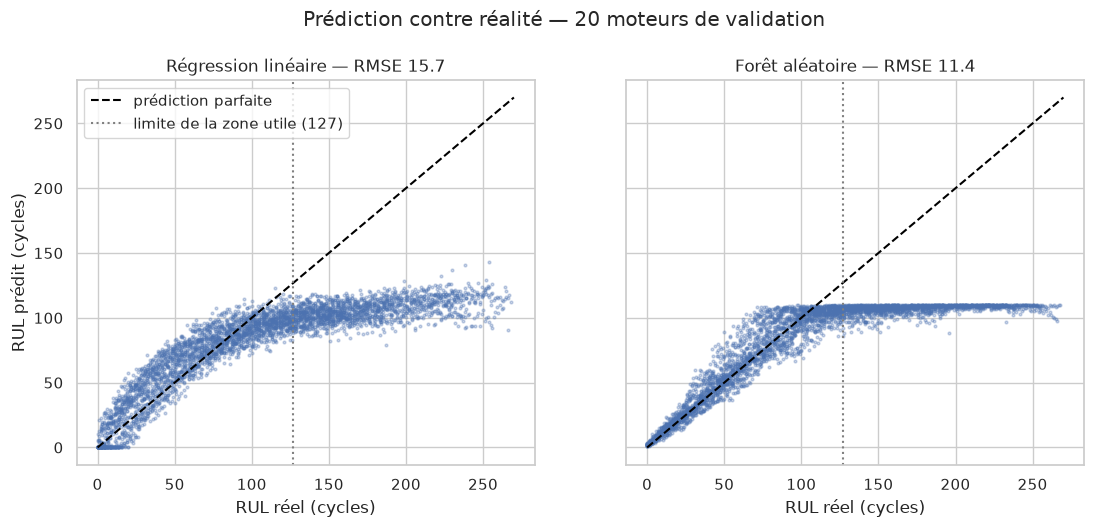

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, model_name in zip(axes, MODEL_NAMES):
    ax.scatter(validation_results["RUL"], validation_results[model_name], s=4, alpha=0.3)
    ax.plot([0, 270], [0, 270], color="black", linestyle="--", label="prédiction parfaite")
    ax.axvline(EVAL_HORIZON, color="gray", linestyle=":", label="limite de la zone utile (127)")
    ax.set(xlabel="RUL réel (cycles)", title=f"{model_name} — RMSE {validation_metrics[model_name]['RMSE']:.1f}")
axes[0].set_ylabel("RUL prédit (cycles)")
axes[0].legend()
fig.suptitle("Prédiction contre réalité — 20 moteurs de validation", y=1.02)
fig.savefig(FIGURE_DIR / "04_validation_pred_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

**Comment lire ce graphique.** Un point sur la diagonale est une prédiction parfaite. Au-delà de 127 (à droite de la ligne pointillée), les prédictions de la forêt restent autour de 110, la valeur du plafond : le modèle dit seulement « moteur en bonne santé », sans chercher le RUL exact. C'est voulu. La régression linéaire, elle, n'est pas bornée : elle peut prédire un peu au-dessus du plafond.

### Erreurs par tranche de RUL

Nous découpons les lignes selon le RUL réel (`pd.cut` range chaque valeur dans une tranche) et nous calculons, pour chaque tranche, l'erreur moyenne absolue (MAE) et le **biais**, c'est-à-dire la moyenne de (prédit − réel) :

- **biais positif** : le modèle annonce **plus** de vie qu'il n'en reste. C'est la direction **dangereuse**, car la panne arrive avant la maintenance prévue ;
- **biais négatif** : le modèle est **prudent**.

In [23]:
# -1 comme première borne pour que la tranche "0-25" contienne aussi RUL = 0
bands = pd.cut(validation_results["RUL"], bins=[-1, 25, 75, 127, 400], labels=["0-25", "26-75", "76-127", "> 127"])
band_rows = []
for model_name in MODEL_NAMES:
    errors = validation_results[model_name] - validation_results["RUL"]
    for band_name in ["0-25", "26-75", "76-127", "> 127"]:
        band_errors = errors[bands == band_name]
        band_rows.append({"modèle": model_name, "tranche de RUL": band_name,
                          "MAE": band_errors.abs().mean(), "biais": band_errors.mean()})
band_table = pd.DataFrame(band_rows)
print("Erreur moyenne absolue (MAE) par tranche :")
display(band_table.pivot(index="tranche de RUL", columns="modèle", values="MAE").round(1))
print("Biais (moyenne de prédit - réel) par tranche :")
band_table.pivot(index="tranche de RUL", columns="modèle", values="biais").round(1)

Erreur moyenne absolue (MAE) par tranche :


modèle,Forêt aléatoire,Régression linéaire
tranche de RUL,,
0-25,2.8,11.1
26-75,8.4,13.8
76-127,11.0,12.9
> 127,69.4,70.3


Biais (moyenne de prédit - réel) par tranche :


modèle,Forêt aléatoire,Régression linéaire
tranche de RUL,,
0-25,2.0,5.7
26-75,5.0,11.5
76-127,-4.6,-9.3
> 127,-69.4,-70.3


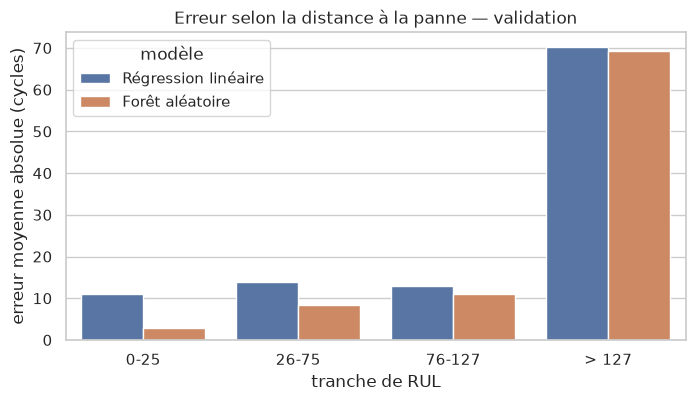

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=band_table, x="tranche de RUL", y="MAE", hue="modèle", ax=ax)
ax.set(ylabel="erreur moyenne absolue (cycles)", title="Erreur selon la distance à la panne — validation")
fig.savefig(FIGURE_DIR / "05_erreurs_par_tranche.png", dpi=150, bbox_inches="tight")
plt.show()

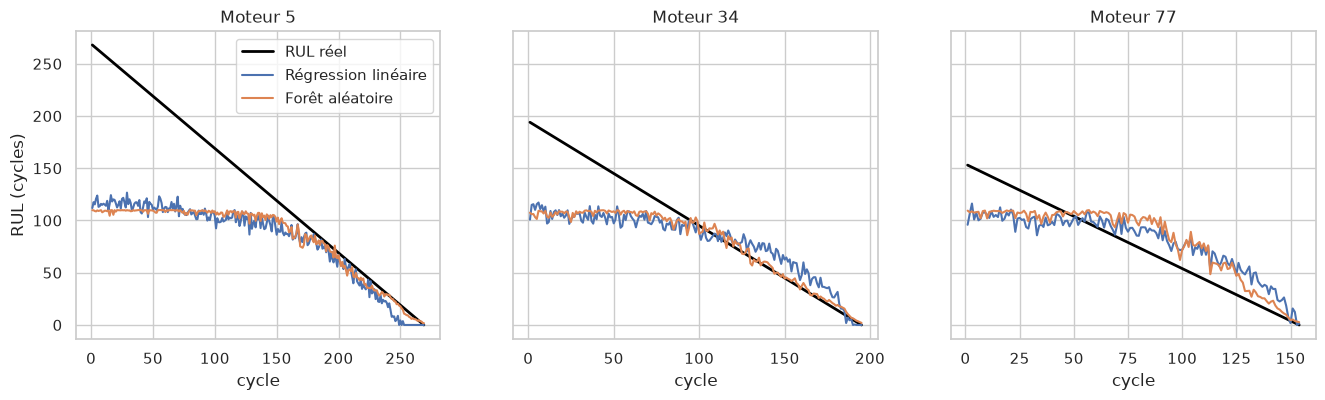

In [25]:
# Trajectoires de 3 moteurs de validation : RUL réel et RUL prédit, cycle après cycle.
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, engine_id in zip(axes, [5, 34, 77]):
    engine = validation_results[validation_results["unit_id"] == engine_id]
    ax.plot(engine["cycle"], engine["RUL"], color="black", linewidth=2, label="RUL réel")
    for model_name in MODEL_NAMES:
        ax.plot(engine["cycle"], engine[model_name], label=model_name)
    ax.set(title=f"Moteur {engine_id}", xlabel="cycle")
axes[0].set_ylabel("RUL (cycles)")
axes[0].legend()
fig.savefig(FIGURE_DIR / "06_trajectoires_validation.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats.** Sur les 20 moteurs de validation, que le modèle n'a jamais vus et qui n'ont servi à aucun choix, la forêt obtient un **RMSE de 11,4** (MAE 8,4, R² 0,90), contre 15,7 pour la régression linéaire. Le classement est le même qu'en validation croisée.

| Tranche de RUL réel | MAE forêt | MAE régression | Biais forêt |
|---|---|---|---|
| 0 à 25 cycles (panne proche) | **2,8** | 11,1 | +2,0 |
| 26 à 75 cycles | 8,4 | 13,8 | +5,0 |
| 76 à 127 cycles | 11,0 | 12,9 | −4,6 |
| plus de 127 cycles (moteur sain) | 69,4 | 70,3 | −69,4 |

**Interprétation.**

- La vérification sur les 20 moteurs **confirme** le choix fait en validation croisée.
- La forêt aléatoire est **très précise près de la panne** : elle se trompe en moyenne de 2,8 cycles quand il reste 25 cycles ou moins. C'est la zone la plus importante pour la maintenance.
- Près de la panne, son biais est légèrement positif : elle annonce un peu trop de vie restante (+2 à +5 cycles en moyenne). Il faudra en tenir compte pour fixer les seuils d'alerte (étape S5).
- Pour les moteurs sains (RUL > 127), l'erreur est grande et négative. C'est l'effet **voulu** du plafond : le modèle répond « au moins 110 cycles » sans chercher le chiffre exact.
- Sur les trajectoires, la prédiction reste plate autour de 110 pendant la phase saine, puis descend avec le RUL réel quand la dégradation devient visible. La courbe de la régression linéaire est plus irrégulière.

### Sur quelles features s'appuie la forêt aléatoire ?

**Ce que nous faisons.** Nous regardons l'**importance** de chaque feature pour la forêt (`feature_importances_`).

**Comment est-elle calculée ?** Chaque question d'un arbre fait baisser l'erreur sur les lignes d'entraînement. L'importance d'une feature est la **baisse d'erreur totale** obtenue par les questions qui l'utilisent, en moyenne sur les 100 arbres. Les valeurs sont ramenées pour que leur somme fasse 1 : 0,20 veut dire « 20 % de l'apprentissage repose sur cette feature ».

**Limite.** C'est une indication de ce qu'utilise le modèle, pas une preuve de cause physique. Quand deux features se ressemblent, l'importance peut se répartir entre elles de façon un peu arbitraire.

Importance par famille : {'moyenne (_mean)': 0.49, 'pente (_slope)': 0.08, 'écart au début (_delta)': 0.42}


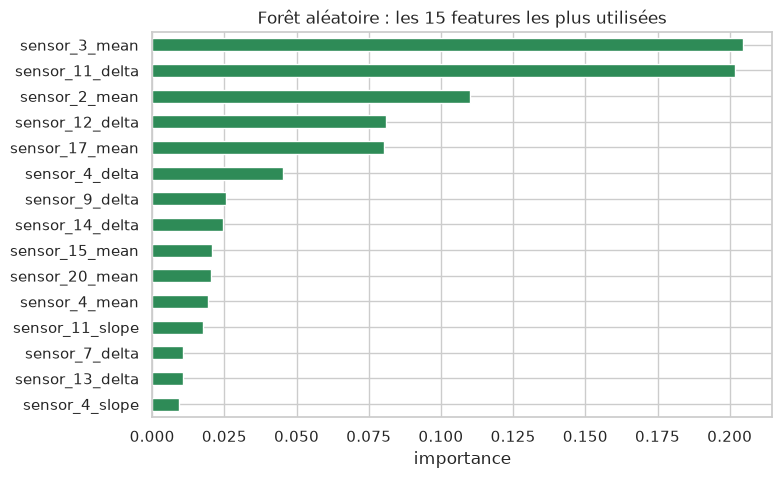

In [26]:
forest = validation_models["Forêt aléatoire"]
importances = pd.Series(forest.feature_importances_, index=HISTORY_FEATURES).sort_values(ascending=False)

# Importance totale de chaque famille de features
family_importance = {
    "moyenne (_mean)": importances[[s + "_mean" for s in SENSORS]].sum(),
    "pente (_slope)": importances[[s + "_slope" for s in SENSORS]].sum(),
    "écart au début (_delta)": importances[[s + "_delta" for s in SENSORS]].sum(),
}
print("Importance par famille :", {k: round(float(v), 2) for k, v in family_importance.items()})

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(15).sort_values().plot.barh(ax=ax, color="seagreen")
ax.set(xlabel="importance", title="Forêt aléatoire : les 15 features les plus utilisées")
fig.savefig(FIGURE_DIR / "07_importance_features.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats.** La forêt utilise surtout les **moyennes** (49 % de l'importance totale) et les **écarts au début de vie** (42 %), et beaucoup moins les pentes (8 %). Les features les plus utilisées sont `sensor_3_mean` et `sensor_11_delta`.

**Interprétation.** Le modèle s'appuie bien sur l'historique construit en section 3, en particulier sur le niveau lissé des capteurs et leur changement depuis le début de vie. C'est cohérent avec les deux constats de l'EDA : les mesures sont bruitées, et chaque moteur part d'un niveau différent. Attention, cela ne prouve pas que `sensor_3` *cause* la panne : il est simplement très utile pour la prédire.

## 8. Entraînement final et évaluation sur le test

**Ce que nous faisons.**

1. Tous les choix sont maintenant **figés** : les features, le plafond de chaque modèle, `max_features` et le modèle retenu. Nous ne les modifierons plus.
2. Nous réentraînons chaque modèle sur les **100 moteurs du train** (80 + 20), pour profiter de toutes les données.
3. Nous enregistrons le modèle retenu dans un fichier `.joblib`, puis nous vérifions qu'il se recharge correctement.
4. Pour chaque moteur de test, nous calculons les features sur tout son historique, puis nous gardons **son dernier cycle observé**. C'est le moment où l'on demande : « combien de cycles lui reste-t-il ? ».
5. Nous lisons `RUL_FD001.txt`, **une seule fois dans ce notebook**, et nous comparons.

**Pourquoi réentraîner sur les 100 moteurs ?** Les choix sont faits ; plus de moteurs donnent un modèle un peu plus précis. Les 20 moteurs de validation ont déjà joué leur rôle de contrôle.

Les deux modèles sont évalués sur le test pour comparaison, mais le **résultat officiel** est celui du modèle retenu par la validation croisée.

### Deux façons de mesurer l'erreur

Les chiffres de validation et de test ne mesurent pas exactement la même chose :

| | Validation (croisée et 20 moteurs) | Test NASA |
|---|---|---|
| Moteurs | suivis **jusqu'à la panne** | arrêtés **avant** la panne |
| Lignes évaluées | **toutes les lignes** avec un RUL réel ≤ 127 | **une seule par moteur** : son dernier cycle observé |
| RUL évalués | de 0 à 127 | de 7 à 145 |
| Nombre de prédictions évaluées | plusieurs milliers | 100 |

La validation mesure la qualité du modèle **tout au long de la fin de vie** d'un moteur. Le test reproduit la question réelle : « ce moteur a tourné jusqu'ici, combien de cycles lui reste-t-il ? ». C'est la mesure officielle utilisée pour comparer les travaux sur C-MAPSS.

### Historique honnête des lectures du jeu de test

En principe, le fichier `RUL_FD001.txt` ne doit être lu **qu'une seule fois**. Dans ce projet, il a déjà été lu par des versions précédentes de la baseline :

| Version | Modèle | RMSE test | Comment les choix ont été faits |
|---|---|---|---|
| Version 1 | Ridge, mesures du cycle courant | 22,69 | validation croisée |
| Version 2 | forêt aléatoire, 62 features | 14,23 | validation croisée |
| Prototype simplifié | forêt aléatoire, 42 features (variante proche), `max_features` = 1,0 | 17,05 | aucun : prototype |
| **Version actuelle** | forêt aléatoire, 42 features, `max_features` = 0,33 | ce notebook | validation croisée |

Après le prototype (17,05), d'autres variantes ont été comparées, **uniquement sur les données d'entraînement et de validation**. Le test n'a donc jamais servi directement à choisir. Mais le fait de connaître ce premier score a orienté la recherche. **Le score test de ce notebook n'est donc pas une évaluation totalement indépendante** : il est probablement un peu optimiste.

**Ce que nous faisons pour limiter ce biais :**

1. Tous les choix (features, plafond, modèle, `max_features`) sont faits par une **règle écrite à l'avance** : le plus petit RMSE moyen en validation croisée sur les 80 moteurs d'entraînement. Cette règle ne dépend pas du test.
2. Les **20 moteurs de validation** donnent une deuxième estimation, qui n'a servi à aucun choix.
3. **Pour S4**, le protocole est fixé dès maintenant : choix uniquement par validation croisée, puis une seule lecture du test à la fin.

Une évaluation parfaitement indépendante demanderait des données jamais consultées pendant le projet.

In [27]:
final_models = {}
for model_name in MODEL_NAMES:
    model = create_model(model_name, SELECTED_MAX_FEATURES)
    target = train_feat["RUL"].clip(upper=best_cap[model_name])      # plafond retenu : 110
    model.fit(train_feat[HISTORY_FEATURES], target)
    final_models[model_name] = model
print("Modèles finaux entraînés sur", train_feat["unit_id"].nunique(), "moteurs.")

Modèles finaux entraînés sur 100 moteurs.


**Sauvegarde du modèle (`joblib`).** `joblib.dump` enregistre le modèle entraîné dans un fichier, avec tout ce qu'il faut pour le réutiliser plus tard (la future API de l'étape S6, par exemple) : la liste et l'ordre des 42 features, les 14 capteurs, la taille de la fenêtre, le début de vie et le plafond. `joblib.load` relit ce fichier. Nous vérifions que le modèle rechargé donne les **mêmes prédictions** que le modèle en mémoire.

In [28]:
model_path = ARTIFACT_DIR / "baseline_rul_fd001.joblib"
model_bundle = {"model": final_models[SELECTED_MODEL], "model_name": SELECTED_MODEL, "features": HISTORY_FEATURES,
                "sensors": SENSORS, "window": WINDOW, "n_start": N_START, "rul_cap": best_cap[SELECTED_MODEL],
                "max_features": SELECTED_MAX_FEATURES}
joblib.dump(model_bundle, model_path)

reloaded = joblib.load(model_path)
sample = train_feat[reloaded["features"]].head(200)              # quelques lignes pour comparer
assert reloaded["features"] == HISTORY_FEATURES                  # mêmes features, dans le même ordre
assert np.allclose(reloaded["model"].predict(sample), final_models[SELECTED_MODEL].predict(sample))
print("Modèle retenu enregistré et rechargé :", SELECTED_MODEL, "— plafond", reloaded["rul_cap"])

Modèle retenu enregistré et rechargé : Forêt aléatoire — plafond 110


In [29]:
test_path = RAW_DIR / "test_FD001.txt"
test_df = pd.read_csv(test_path, sep=r"\s+", header=None, names=COLUMN_NAMES)
assert len(test_df) == eda_summary["test_rows"]                   # même fichier que dans l'EDA

test_feat = add_history_features(test_df, SENSORS, WINDOW, N_START)        # features sur tout l'historique
test_last = test_feat.groupby("unit_id").tail(1).sort_values("unit_id")   # puis le dernier cycle de chaque moteur
print(len(test_last), "moteurs de test, de", test_last["cycle"].min(), "à", test_last["cycle"].max(), "cycles observés")

100 moteurs de test, de 31 à 303 cycles observés


In [30]:
# --- Seule lecture de la vérité terrain du test dans ce notebook ---
true_test_rul = np.loadtxt(RAW_DIR / "RUL_FD001.txt")       # ligne k = vrai RUL du moteur k
assert len(true_test_rul) == len(test_last)                    # une valeur par moteur de test
assert test_last["unit_id"].tolist() == list(range(1, 101))    # moteurs dans l'ordre 1 à 100

test_results = test_last[["unit_id", "cycle"]].rename(columns={"cycle": "last_cycle"})
test_results["RUL_true"] = true_test_rul
test_metrics = {}
for model_name in MODEL_NAMES:
    predictions = final_models[model_name].predict(test_last[HISTORY_FEATURES])
    predictions = np.clip(predictions, 0, None)                 # pas de RUL négatif
    test_results[model_name] = predictions
    test_metrics[model_name] = compute_metrics(true_test_rul, predictions)

pd.DataFrame(test_metrics).T

,MAE,RMSE,R2
Régression linéaire,15.09,19.15,0.79
Forêt aléatoire,10.53,14.40,0.88


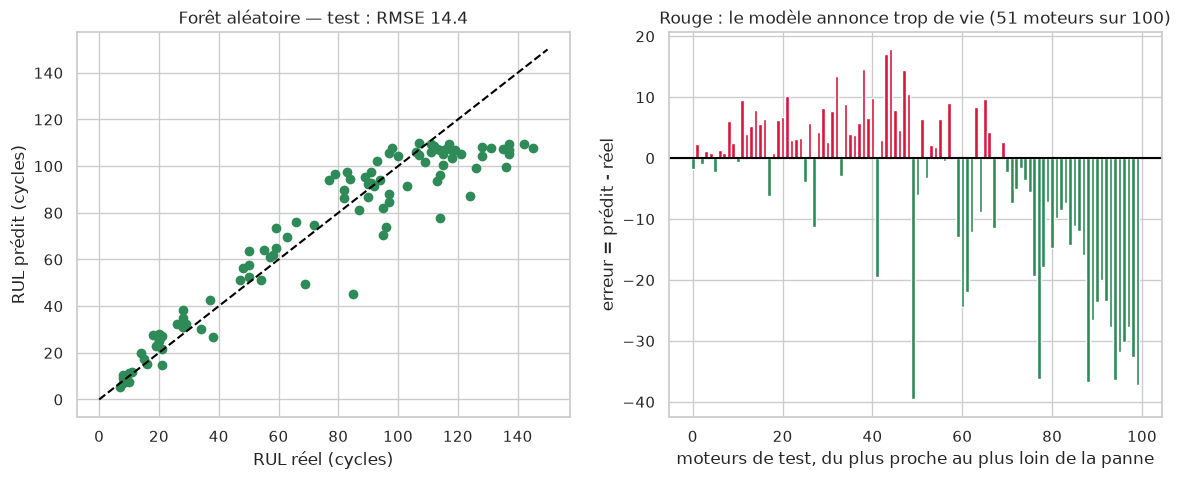

Plus grand dépassement : 17.8 cycles


In [31]:
errors = test_results[SELECTED_MODEL] - test_results["RUL_true"]
n_too_optimistic = int((errors > 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_results["RUL_true"], test_results[SELECTED_MODEL], color="seagreen")
axes[0].plot([0, 150], [0, 150], color="black", linestyle="--")
axes[0].set(xlabel="RUL réel (cycles)", ylabel="RUL prédit (cycles)",
            title=f"{SELECTED_MODEL} — test : RMSE {test_metrics[SELECTED_MODEL]['RMSE']:.1f}")

order = test_results.sort_values("RUL_true")
order_errors = order[SELECTED_MODEL] - order["RUL_true"]
axes[1].bar(range(len(order)), order_errors, color=np.where(order_errors > 0, "crimson", "seagreen"))
axes[1].axhline(0, color="black")
axes[1].set(xlabel="moteurs de test, du plus proche au plus loin de la panne", ylabel="erreur = prédit - réel",
            title=f"Rouge : le modèle annonce trop de vie ({n_too_optimistic} moteurs sur 100)")
fig.savefig(FIGURE_DIR / "08_test_pred_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

print("Plus grand dépassement :", round(float(errors.max()), 1), "cycles")

**Résultats.**

| Modèle | MAE | RMSE | R² |
|---|---|---|---|
| Régression linéaire | 15,1 | 19,1 | 0,79 |
| **Forêt aléatoire (modèle retenu)** | **10,5** | **14,4** | **0,88** |

- Le **résultat officiel** de la baseline est la forêt aléatoire : **RMSE = 14,4 cycles** et **R² = 0,88** sur les 100 moteurs de test (avec la réserve expliquée plus haut sur l'indépendance de ce score).
- 51 moteurs sur 100 reçoivent une prédiction un peu trop optimiste (en rouge), au plus de 17,8 cycles.
- Le test **confirme** le classement obtenu en validation croisée et sur les 20 moteurs de validation.
- Le RMSE du test (14,4) est plus élevé que celui de la validation (11,4). La cellule suivante vérifie deux explications possibles.

**Pourquoi le test est-il moins bon que la validation ?** Vérifions deux explications possibles.

In [32]:
# 1) Moteurs de test encore sains : leur vrai RUL dépasse le plafond, donc le modèle ne peut pas l'atteindre.
healthy = test_results["RUL_true"] > 110
print("Moteurs de test avec un RUL réel > 110 :", healthy.sum())
print("  erreur moyenne sur ces moteurs :", round(float(errors[healthy].mean()), 1), "cycles")

# 2) Moteurs avec peu d'historique : moins de 50 cycles observés.
short = test_results["last_cycle"] < 50
print("Moteurs de test avec moins de 50 cycles :", short.sum())
print("  erreur absolue moyenne :", round(float(errors[short].abs().mean()), 1), "cycles, contre",
      round(float(errors[~short].abs().mean()), 1), "pour les autres")       # ~short : les autres moteurs

Moteurs de test avec un RUL réel > 110 : 28
  erreur moyenne sur ces moteurs : -19.4 cycles
Moteurs de test avec moins de 50 cycles : 7
  erreur absolue moyenne : 14.0 cycles, contre 10.3 pour les autres


**Résultats.**

- **28 moteurs de test** ont un vrai RUL supérieur à 110. Le modèle ne peut pas l'atteindre à cause du plafond, et il les sous-estime en moyenne de 19,4 cycles. C'est une erreur **prudente**, voulue.
- Les **7 moteurs** avec moins de 50 cycles d'historique ont une erreur moyenne de 14,0 cycles, contre 10,3 pour les autres : avec peu d'historique, la prédiction est plus difficile.

**Interprétation.** L'écart entre validation et test s'explique par ces deux effets et par la différence de méthode : la validation évalue toutes les lignes avec un RUL ≤ 127, le test un seul point par moteur, avec des RUL qui peuvent dépasser 127.

## 9. Sauvegarde des résultats

**Ce que nous faisons.** Nous enregistrons les résultats dans des fichiers, pour le rapport et pour S4 :

| Fichier | Contenu |
|---|---|
| `artifacts/baseline_fd001/baseline_metrics.json` | choix retenus, moteurs contrôlés à chaque tour de validation croisée, métriques de validation et de test des deux modèles : **la référence pour S4** |
| `artifacts/baseline_fd001/test_predictions.csv` | RUL réel et prédit pour les 100 moteurs de test |
| `artifacts/baseline_fd001/baseline_rul_fd001.joblib` | modèle retenu et ses réglages, enregistré à la section 8 (non versionné dans Git) |

In [33]:
def rounded(metrics):
    # Arrondit chaque métrique à 4 décimales pour le fichier JSON.
    return {name: round(float(value), 4) for name, value in metrics.items()}


fold_engines = []                                   # moteurs contrôlés à chaque tour (pour S4)
for fit_engines, check_engines in folds:
    fold_engines.append(check_engines)

baseline_metrics = {
    "dataset": "FD001",
    "sensors": SENSORS,
    "features": HISTORY_FEATURES,
    "window": WINDOW,
    "n_start": N_START,
    "evaluation_horizon": EVAL_HORIZON,
    "validation_engines": VALIDATION_ENGINES,
    "random_forest_params": {"n_estimators": 100, "min_samples_leaf": 5, "max_features": SELECTED_MAX_FEATURES},
    "cross_validation": {"method": "GroupKFold(5) sur les 80 moteurs d'entraînement",
                         "fold_engines": fold_engines,
                         "rmse_mean": {m: round(float(best_rmse[m]), 4) for m in MODEL_NAMES}},
    "rul_cap": best_cap,
    "selected_model": SELECTED_MODEL,
    "validation_metrics_zone": {m: rounded(validation_metrics[m]) for m in MODEL_NAMES},
    "test_set_history": ("le test FD001 a déjà été lu par des versions précédentes (RMSE 22,69 ; 14,23 ; 17,05) : "
                         "ce score n'est pas une évaluation totalement indépendante"),
    "test_metrics": {m: rounded(test_metrics[m]) for m in MODEL_NAMES},
    "test_late_predictions_selected_model": n_too_optimistic,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__},
}
(ARTIFACT_DIR / "baseline_metrics.json").write_text(json.dumps(baseline_metrics, indent=2, ensure_ascii=False),
                                                    encoding="utf-8")
test_results.round(4).to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
print("Résultats enregistrés dans", ARTIFACT_DIR)

Résultats enregistrés dans ../artifacts/baseline_fd001


## 10. Conclusion

### Résultats

| Modèle (plafond 110) | RMSE validation croisée (80 moteurs) | RMSE validation (20 moteurs) | RMSE test | MAE test | R² test |
|---|---|---|---|---|---|
| Régression linéaire | 16,8 | 15,7 | 19,1 | 15,1 | 0,79 |
| **Forêt aléatoire (retenue)** | **12,8** | **11,4** | **14,4** | **10,5** | **0,88** |

### Ce que nous retenons

1. **L'historique récent est la clé** : moyenne, pente et écart au début de vie réduisent fortement l'erreur, surtout pour la forêt aléatoire.
2. **Le RUL plafonné à 110 cycles** donne les meilleurs résultats pour les deux modèles.
3. **La forêt aléatoire** est retenue, car elle a le plus petit RMSE en validation croisée. Une explication probable : elle représente mieux une relation non linéaire, comme la dégradation « lente puis accélérée ».
4. **La méthode est fiable** : séparation par moteur, features calculées avec le passé uniquement, choix par validation croisée, vérification sur 20 moteurs jamais utilisés, puis test.

### Limites

- Le modèle ne regarde que les 30 derniers cycles, avec des statistiques choisies à la main.
- Au-delà de 110 cycles, il ne distingue pas un moteur neuf d'un moteur à mi-vie.
- Près de la panne, il annonce parfois un peu trop de vie restante.
- Il donne une valeur sans intervalle de confiance.
- Les données sont simulées, et la validation finale ne compte que 20 moteurs.
- Le jeu de test a déjà été lu par des versions précédentes : son score n'est pas totalement indépendant (section 8).

### Référence pour l'étape S4 (LSTM / GRU)

Le modèle séquentiel devra être évalué **exactement de la même façon** :

- mêmes 5 tours de validation croisée sur les 80 moteurs (`fold_engines` dans `baseline_metrics.json`, ou `ml.src.evaluation.engine_folds`) ;
- mêmes 20 moteurs de validation ;
- même zone d'évaluation (RUL réel ≤ 127) et RUL plafonné ;
- 30 cycles d'historique au maximum ;
- test au dernier cycle observé, avec une seule lecture de `RUL_FD001.txt` à la fin.

**À battre :** RMSE moyen de **12,8** en validation croisée, **11,4** sur les 20 moteurs de validation et **14,4** sur le test.

**Ce qui sera partagé, et ce qui ne le sera pas.** Le LSTM/GRU recevra directement des **fenêtres de mesures brutes** des capteurs (par exemple les 30 derniers cycles des 14 capteurs), et non les 42 features calculées ici à la main. Ce qui doit rester identique, c'est le **protocole de comparaison** : mêmes données FD001, même calcul du RUL, mêmes moteurs, mêmes 5 groupes, mêmes métriques et même zone d'évaluation. Contrairement à la baseline, le LSTM aura besoin d'une **normalisation**, calculée sur les moteurs d'apprentissage de chaque tour uniquement.

## 11. Vérifications finales

> **Cellules de vérification technique.** Ces deux cellules contrôlent la cohérence du projet. Elles ne font partie ni de la méthode ni des résultats, et il n'est pas nécessaire de les détailler pendant la soutenance.

**1. Le code réutilisable `ml/src` donne les mêmes résultats que ce notebook.** Les fonctions de ce notebook sont aussi enregistrées dans `ml/src/`, avec les mêmes noms, pour être réutilisées en S4 (LSTM/GRU) et dans la future API. Nous vérifions qu'elles produisent exactement les mêmes features, le même RUL, les mêmes métriques et les mêmes 5 groupes de moteurs. Les tests `pytest` font les mêmes vérifications sur de petits exemples.

In [34]:
import sys
sys.path.append(str(PROJECT_ROOT.resolve()))       # pour pouvoir importer le dossier ml/ du projet
from ml.src import data, evaluation, features

train_src = features.add_history_features(data.add_rul(data.load_cmapss(train_path)), SENSORS, WINDOW, N_START)
assert np.array_equal(train_src[HISTORY_FEATURES].to_numpy(), train_feat[HISTORY_FEATURES].to_numpy())
assert np.array_equal(train_src["RUL"].to_numpy(), train_feat["RUL"].to_numpy())
assert features.history_feature_names(SENSORS) == HISTORY_FEATURES
assert evaluation.compute_metrics([10, 50, 100], [12, 40, 110]) == compute_metrics([10, 50, 100], [12, 40, 110])
assert evaluation.engine_folds(train_part) == folds        # mêmes moteurs dans chacun des 5 tours
print("ml/src et le notebook donnent les mêmes résultats.")

ml/src et le notebook donnent les mêmes résultats.


**2. Les chiffres cités dans le texte correspondent à l'exécution.** Chaque ligne de la liste `checks` compare une valeur calculée au chiffre écrit dans le texte. Si le code ou les données changent, cette cellule s'arrête avec une erreur au lieu de laisser un texte faux.

In [35]:
def rmse_of(table, model_name, column, option):
    # RMSE moyen de la ligne (modèle, option) d'un tableau d'expérience.
    row = table[(table["modèle"] == model_name) & (table[column] == option)]
    return row["RMSE"].iloc[0]


def band_value(model_name, band_name, column):
    # MAE ou biais d'un modèle pour une tranche de RUL (section 7).
    row = band_table[(band_table["modèle"] == model_name) & (band_table["tranche de RUL"] == band_name)]
    return row[column].iloc[0]


rf, lr = "Forêt aléatoire", "Régression linéaire"

# Chaque ligne : (ce qui est vérifié, valeur calculée, valeur écrite dans le texte, nombre de décimales)
checks = [
    ("exp. 1 — régression, instantanées", rmse_of(experiment_1, lr, "features", "instantanées (14)"), 21.6, 1),
    ("exp. 1 — régression, historique", rmse_of(experiment_1, lr, "features", "historique (42)"), 18.2, 1),
    ("exp. 1 — forêt, instantanées", rmse_of(experiment_1, rf, "features", "instantanées (14)"), 20.7, 1),
    ("exp. 1 — forêt, historique", rmse_of(experiment_1, rf, "features", "historique (42)"), 13.8, 1),
    ("exp. 1 — écart-type régression, instantanées", experiment_1["RMSE écart-type"].iloc[0], 2.6, 1),
    ("exp. 1 — écart-type forêt, instantanées", experiment_1["RMSE écart-type"].iloc[2], 3.1, 1),
    ("exp. 2 — régression sans plafond", rmse_of(experiment_2, lr, "plafond", "sans"), 32.5, 1),
    ("exp. 2 — régression 100", rmse_of(experiment_2, lr, "plafond", 100), 17.1, 1),
    ("exp. 2 — régression 110", rmse_of(experiment_2, lr, "plafond", 110), 16.8, 1),
    ("exp. 2 — régression 125", rmse_of(experiment_2, lr, "plafond", 125), 18.2, 1),
    ("exp. 2 — régression 140", rmse_of(experiment_2, lr, "plafond", 140), 20.7, 1),
    ("exp. 2 — forêt sans plafond", rmse_of(experiment_2, rf, "plafond", "sans"), 23.7, 1),
    ("exp. 2 — forêt 100", rmse_of(experiment_2, rf, "plafond", 100), 13.5, 1),
    ("exp. 2 — forêt 110", rmse_of(experiment_2, rf, "plafond", 110), 12.8, 1),
    ("exp. 2 — forêt 125", rmse_of(experiment_2, rf, "plafond", 125), 13.8, 1),
    ("exp. 2 — forêt 140", rmse_of(experiment_2, rf, "plafond", 140), 15.7, 1),
    ("exp. 3 — max_features 0,33", experiment_3["RMSE"].iloc[0], 12.85, 2),
    ("exp. 3 — max_features 1,0", experiment_3["RMSE"].iloc[1], 13.16, 2),
    ("validation — forêt RMSE", validation_metrics[rf]["RMSE"], 11.4, 1),
    ("validation — forêt MAE", validation_metrics[rf]["MAE"], 8.4, 1),
    ("validation — forêt R²", validation_metrics[rf]["R2"], 0.90, 2),
    ("validation — régression RMSE", validation_metrics[lr]["RMSE"], 15.7, 1),
    ("tranche 0-25 — MAE forêt", band_value(rf, "0-25", "MAE"), 2.8, 1),
    ("tranche 26-75 — MAE forêt", band_value(rf, "26-75", "MAE"), 8.4, 1),
    ("tranche 76-127 — MAE forêt", band_value(rf, "76-127", "MAE"), 11.0, 1),
    ("tranche > 127 — MAE forêt", band_value(rf, "> 127", "MAE"), 69.4, 1),
    ("tranche 0-25 — MAE régression", band_value(lr, "0-25", "MAE"), 11.1, 1),
    ("tranche 26-75 — MAE régression", band_value(lr, "26-75", "MAE"), 13.8, 1),
    ("tranche 76-127 — MAE régression", band_value(lr, "76-127", "MAE"), 12.9, 1),
    ("tranche > 127 — MAE régression", band_value(lr, "> 127", "MAE"), 70.3, 1),
    ("tranche 0-25 — biais forêt", band_value(rf, "0-25", "biais"), 2.0, 1),
    ("tranche 26-75 — biais forêt", band_value(rf, "26-75", "biais"), 5.0, 1),
    ("tranche 76-127 — biais forêt", band_value(rf, "76-127", "biais"), -4.6, 1),
    ("tranche > 127 — biais forêt", band_value(rf, "> 127", "biais"), -69.4, 1),
    ("importance des moyennes", family_importance["moyenne (_mean)"], 0.49, 2),
    ("importance des pentes", family_importance["pente (_slope)"], 0.08, 2),
    ("importance des écarts", family_importance["écart au début (_delta)"], 0.42, 2),
    ("test — forêt RMSE", test_metrics[rf]["RMSE"], 14.4, 1),
    ("test — forêt MAE", test_metrics[rf]["MAE"], 10.5, 1),
    ("test — forêt R²", test_metrics[rf]["R2"], 0.88, 2),
    ("test — régression RMSE", test_metrics[lr]["RMSE"], 19.1, 1),
    ("test — régression MAE", test_metrics[lr]["MAE"], 15.1, 1),
    ("test — régression R²", test_metrics[lr]["R2"], 0.79, 2),
    ("test — plus grand dépassement", errors.max(), 17.8, 1),
    ("test — erreur moyenne des moteurs sains", errors[healthy].mean(), -19.4, 1),
    ("test — erreur, historique < 50 cycles", errors[short].abs().mean(), 14.0, 1),
    ("test — erreur, historique >= 50 cycles", errors[~short].abs().mean(), 10.3, 1),
]
for description, value, expected, digits in checks:
    assert round(float(value), digits) == expected, description

# Choix et comptages cités dans le texte
assert best_cap == {lr: 110, rf: 110}
assert SELECTED_MODEL == rf and SELECTED_MAX_FEATURES == 0.33
assert experiment_1["RMSE écart-type"].iloc[1] < 0.8 and experiment_1["RMSE écart-type"].iloc[3] < 0.8
assert list(importances.index[:2]) == ["sensor_3_mean", "sensor_11_delta"]
assert n_too_optimistic == 51 and healthy.sum() == 28 and short.sum() == 7
assert true_test_rul.min() == 7 and true_test_rul.max() == 145
print(len(checks), "chiffres vérifiés : tous les chiffres cités correspondent à l'exécution.")

47 chiffres vérifiés : tous les chiffres cités correspondent à l'exécution.
